In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
# If there are missing values:
# For categorical features, replace them with 'NA'
# For numerical features, replace with with 0.0
missing = df.isnull().sum()

if missing.sum() > 0:
    for col in df.columns:
        if df[col].dtype == 'str':
            df[col] = df[col].fillna('NA')
        elif pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(0.0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [6]:
# What is the most frequent observation (mode) for the column industry?
df['industry'].mode()[0]

'technology'

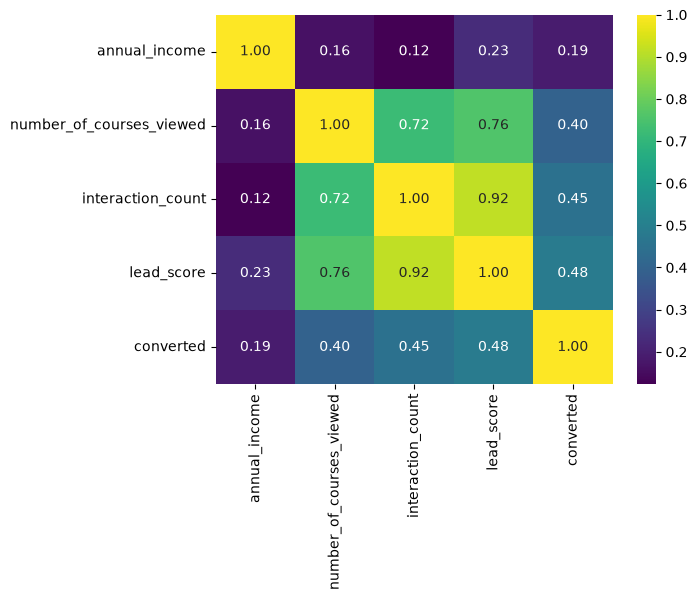

In [7]:
# Create the correlation matrix for the numerical features of your dataset.
# In a correlation matrix, you compute the correlation coefficient between every pair of features.
sns.heatmap(df.corr(numeric_only=True), cmap='viridis',annot=True, fmt='.2f')
plt.show()

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']


In [12]:
# Calculate the mutual information score between 'converted' and other categorical variables in the dataset. Use the training set only.
cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()
X_cat = OrdinalEncoder().fit_transform(df_train[cat_cols])

mutual_info = mutual_info_classif(X_cat, y_train)
mutual_info_scores = pd.Series(mutual_info, index=cat_cols).sort_values(ascending=False)
mutual_info_scores

/tmp/ipykernel_49591/627637779.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object']).columns.tolist()


employment_status    0.024856
lead_source          0.017498
industry             0.004567
location             0.000000
dtype: float64

In [16]:
X_train = pd.get_dummies(df_train, drop_first=True)
X_val = pd.get_dummies(df_val, drop_first=True)
X_test = pd.get_dummies(df_test, drop_first=True)

In [ ]:
# Now let's train a logistic regression.
# Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
# Fit the model on the training dataset.
# To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
# Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [19]:
# Accuracy on the validation dataset
y_pred = model.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 2))

Accuracy: 0.65


In [21]:
# Baseline accuracy using all features
baseline_model = clone(model)
baseline_model.fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_val, baseline_model.predict(X_val))

results = []

for feature in X_train.columns:
    # Train from scratch with this feature removed
    model_without_feature = clone(model)
    model_without_feature.fit(X_train.drop(columns=[feature]), y_train)

    accuracy_without = accuracy_score(
        y_val,
        model_without_feature.predict(X_val.drop(columns=[feature]))
    )

    results.append({
        "feature": feature,
        "accuracy_without": accuracy_without,
        "accuracy_difference": baseline_accuracy - accuracy_without,
    })

results_df = pd.DataFrame(results).sort_values("accuracy_difference")
results_df

,feature,accuracy_without,accuracy_difference
0,annual_income,0.725,-0.080
4,lead_source_events,0.647,-0.002
5,lead_source_organic_search,0.646,-0.001
14,industry_technology,0.646,-0.001
13,industry_retail,0.646,-0.001
11,industry_healthcare,0.646,-0.001
9,industry_education,0.646,-0.001
8,lead_source_social_media,0.646,-0.001
20,location_asia,0.646,-0.001
22,location_north_america,0.646,-0.001


In [22]:
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    model_c = clone(model).set_params(C=C)
    model_c.fit(X_train, y_train)

    accuracy = accuracy_score(y_val, model_c.predict(X_val))
    print(f"C={C}: {accuracy:.3f}")

C=1e-06: 0.598
C=1e-05: 0.598
C=0.0001: 0.613
C=0.001: 0.645
